# DataPrep – Transaction Data Cleaning & Analysis

This Google Colab notebook uses the UCI Online Retail II dataset to practise data inspection, cleaning, processing, Pandas and NumPy analysis.

In [109]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import requests
import zipfile
import warnings
import seaborn as sns
import matplotlib.pyplot as plt
sns.set_theme(style="whitegrid", context="notebook", palette="Set2")
plt.rcParams["figure.dpi"] = 110
warnings.filterwarnings("ignore")

In [110]:
# Download and extract the dataset
url = "https://archive.ics.uci.edu/static/public/502/online+retail+ii.zip"
response = requests.get(url, timeout=120)
response.raise_for_status()

with open("retail.zip", "wb") as f:
    f.write(response.content)

with zipfile.ZipFile("retail.zip", "r") as z:
    z.extractall("retail_data")

print("Dataset downloaded and extracted successfully!")

Dataset downloaded and extracted successfully!


In [111]:
# Load both sheets into one DataFrame
file_path = "retail_data/online_retail_II.xlsx"
sheets = pd.read_excel(file_path, sheet_name=None)
df = pd.concat(sheets.values(), ignore_index=True)

print("Dataset loaded successfully!")
print("Shape:", df.shape)
display(df.head())

Dataset loaded successfully!
Shape: (1067371, 8)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [112]:
# Inspect the dataset
print("Total records:", len(df))
print("Total columns:", len(df.columns))
print("\nColumn names:", df.columns.tolist())
print("\nData types:")
print(df.dtypes)
df.info()

Total records: 1067371
Total columns: 8

Column names: ['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country']

Data types:
Invoice                object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
Price                 float64
Customer ID           float64
Country                object
dtype: object
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype         
---  ------       --------------    -----         
 0   Invoice      1067371 non-null  object        
 1   StockCode    1067371 non-null  object        
 2   Description  1062989 non-null  object        
 3   Quantity     1067371 non-null  int64         
 4   InvoiceDate  1067371 non-null  datetime64[ns]
 5   Price        1067371 non-null  float64       
 6   Customer ID  824364 non-null   float64       
 7   

In [113]:
# Summary statistics
display(df.describe(include="all").T)

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
Invoice,1067371.0,53628.0,537434.0,1350.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
StockCode,1067371,5305,85123A,5829,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Description,1062989,5698,WHITE HANGING HEART T-LIGHT HOLDER,5918,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,1067371.0,NaN,NaN,NaN,9.938898,-80995.0,1.0,3.0,10.0,80995.0,172.705794
InvoiceDate,1067371,NaN,NaN,NaN,2011-01-02 21:13:55.394028544,2009-12-01 07:45:00,2010-07-09 09:46:00,2010-12-07 15:28:00,2011-07-22 10:23:00,2011-12-09 12:50:00,NaN
Price,1067371.0,NaN,NaN,NaN,4.649388,-53594.36,1.25,2.1,4.15,38970.0,123.553059
Customer ID,824364.0,NaN,NaN,NaN,15324.638504,12346.0,13975.0,15255.0,16797.0,18287.0,1697.46445
Country,1067371,43,United Kingdom,981330,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [114]:
# Check missing values
missing = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Percentage": (df.isnull().mean() * 100).round(2)
})
display(missing)

,Missing Count,Percentage
Invoice,0,0.00
StockCode,0,0.00
Description,4382,0.41
Quantity,0,0.00
InvoiceDate,0,0.00
Price,0,0.00
Customer ID,243007,22.77
Country,0,0.00


In [115]:
# Check duplicate records
print("Duplicate records:", df.duplicated().sum())
display(df[df.duplicated(keep=False)].head(10))

Duplicate records: 34335


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
362,489517,21913,VINTAGE SEASIDE JIGSAW PUZZLES,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
363,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
365,489517,21821,GLITTER STAR GARLAND WITH BELLS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
367,489517,22319,HAIRCLIPS FORTIES FABRIC ASSORTED,12,2009-12-01 11:34:00,0.65,16329.0,United Kingdom
368,489517,22130,PARTY CONE CHRISTMAS DECORATION,6,2009-12-01 11:34:00,0.85,16329.0,United Kingdom
371,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
379,489517,21491,SET OF THREE VINTAGE GIFT WRAPS,1,2009-12-01 11:34:00,1.95,16329.0,United Kingdom
383,489517,22130,PARTY CONE CHRISTMAS DECORATION,6,2009-12-01 11:34:00,0.85,16329.0,United Kingdom
384,489517,22319,HAIRCLIPS FORTIES FABRIC ASSORTED,12,2009-12-01 11:34:00,0.65,16329.0,United Kingdom
385,489517,21913,VINTAGE SEASIDE JIGSAW PUZZLES,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom


In [116]:
# Check unique values and blank text values
print("Unique values per column:")
print(df.nunique())

print("\nBlank text values:")
print(df.astype("string").apply(lambda col: col.str.strip().eq("").sum()))

Unique values per column:
Invoice        53628
StockCode       5305
Description     5698
Quantity        1057
InvoiceDate    47635
Price           2807
Customer ID     5942
Country           43
dtype: int64

Blank text values:
Invoice        0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
Price          0
Customer ID    0
Country        0
dtype: int64


In [117]:
# Check negative, positive and zero quantities
print("Negative quantities:", (df["Quantity"] < 0).sum())
print("Positive quantities:", (df["Quantity"] > 0).sum())
print("Zero quantities:", (df["Quantity"] == 0).sum())
display(df[df["Quantity"] < 0].head())

Negative quantities: 22950
Positive quantities: 1044421
Zero quantities: 0


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
178,C489449,22087,PAPER BUNTING WHITE LACE,-12,2009-12-01 10:33:00,2.95,16321.0,Australia
179,C489449,85206A,CREAM FELT EASTER EGG BASKET,-6,2009-12-01 10:33:00,1.65,16321.0,Australia
180,C489449,21895,POTTING SHED SOW 'N' GROW SET,-4,2009-12-01 10:33:00,4.25,16321.0,Australia
181,C489449,21896,POTTING SHED TWINE,-6,2009-12-01 10:33:00,2.10,16321.0,Australia
182,C489449,22083,PAPER CHAIN KIT RETRO SPOT,-12,2009-12-01 10:33:00,2.95,16321.0,Australia


In [118]:
# Check price values
print("Negative prices:", (df["Price"] < 0).sum())
print("Zero prices:", (df["Price"] == 0).sum())
display(df[df["Price"] <= 0].head())

Negative prices: 5
Zero prices: 6202


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
263,489464,21733,85123a mixed,-96,2009-12-01 10:52:00,0.0,NaN,United Kingdom
283,489463,71477,short,-240,2009-12-01 10:52:00,0.0,NaN,United Kingdom
284,489467,85123A,21733 mixed,-192,2009-12-01 10:53:00,0.0,NaN,United Kingdom
470,489521,21646,NaN,-50,2009-12-01 11:44:00,0.0,NaN,United Kingdom
3114,489655,20683,NaN,-44,2009-12-01 17:26:00,0.0,NaN,United Kingdom


In [119]:
# Identify cancelled invoices
cancelled = df[df["Invoice"].astype(str).str.startswith("C")]
print("Cancelled invoice records:", len(cancelled))
display(cancelled.head())

Cancelled invoice records: 19494


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
178,C489449,22087,PAPER BUNTING WHITE LACE,-12,2009-12-01 10:33:00,2.95,16321.0,Australia
179,C489449,85206A,CREAM FELT EASTER EGG BASKET,-6,2009-12-01 10:33:00,1.65,16321.0,Australia
180,C489449,21895,POTTING SHED SOW 'N' GROW SET,-4,2009-12-01 10:33:00,4.25,16321.0,Australia
181,C489449,21896,POTTING SHED TWINE,-6,2009-12-01 10:33:00,2.10,16321.0,Australia
182,C489449,22083,PAPER CHAIN KIT RETRO SPOT,-12,2009-12-01 10:33:00,2.95,16321.0,Australia


In [120]:
# Remove duplicate rows
before = len(df)
df = df.drop_duplicates().copy()
print("Original records:", before)
print("Records after duplicate removal:", len(df))
print("Duplicates removed:", before - len(df))

Original records: 1067371
Records after duplicate removal: 1033036
Duplicates removed: 34335


In [121]:
# Correct data types
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"], errors="coerce")
df["Quantity"] = pd.to_numeric(df["Quantity"], errors="coerce")
df["Price"] = pd.to_numeric(df["Price"], errors="coerce")
df["Customer ID"] = pd.to_numeric(df["Customer ID"], errors="coerce").astype("Int64")

print(df.dtypes)

Invoice                object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
Price                 float64
Customer ID             Int64
Country                object
dtype: object


In [122]:
# Handle missing values
df["Description"] = df["Description"].fillna("Unknown")
df.dropna(subset=["Invoice", "StockCode", "InvoiceDate", "Quantity", "Price"], inplace=True)

print("Missing values after cleaning:")
print(df.isnull().sum())

Missing values after cleaning:
Invoice             0
StockCode           0
Description         0
Quantity            0
InvoiceDate         0
Price               0
Customer ID    235151
Country             0
dtype: int64


In [123]:
# Clean text columns
for col in ["Description", "Country", "StockCode"]:
    df[col] = df[col].apply(lambda value: value.strip() if isinstance(value, str) else value)

print("Text cleaning completed!")

Text cleaning completed!


In [124]:
# Convert selected columns into NumPy arrays
quantity = df["Quantity"].to_numpy()
price = df["Price"].to_numpy()

print("Quantity array sample:", quantity[:10])
print("Price array sample:", price[:10])

Quantity array sample: [12 12 12 48 24 24 24 10 12 12]
Price array sample: [6.95 6.75 6.75 2.1  1.25 1.65 1.25 5.95 2.55 3.75]


In [125]:
# NumPy statistical operations
print("Quantity analysis")
print("Sum:", np.sum(quantity))
print("Mean:", np.mean(quantity))
print("Median:", np.median(quantity))
print("Minimum:", np.min(quantity))
print("Maximum:", np.max(quantity))
print("Standard deviation:", np.std(quantity))

Quantity analysis
Sum: 10409779
Mean: 10.076879218149223
Median: 3.0
Minimum: -80995
Maximum: 80995
Standard deviation: 175.19754319954396


In [126]:
# Classify transactions using NumPy
df["TransactionType"] = np.where(
    df["Quantity"] < 0, "Return",
    np.where(df["Quantity"] == 0, "Zero", "Sale")
)
print(df["TransactionType"].value_counts())

TransactionType
Sale      1010540
Return      22496
Name: count, dtype: int64


In [127]:
# Calculate transaction amount
df["TotalAmount"] = np.multiply(df["Quantity"], df["Price"])
display(df[["Quantity", "Price", "TotalAmount"]].head())

,Quantity,Price,TotalAmount
0,12,6.95,83.4
1,12,6.75,81.0
2,12,6.75,81.0
3,48,2.10,100.8
4,24,1.25,30.0


In [128]:
# Analyse valid sales (positive quantity and price)
sales = df[(df["Quantity"] > 0) & (df["Price"] > 0)].copy()

print("Total revenue:", sales["TotalAmount"].sum())
print("Total sales records:", len(sales))
print("Unique customers:", sales["Customer ID"].nunique())
print("Unique products:", sales["StockCode"].nunique())

Total revenue: 20476634.018
Total sales records: 1007914
Unique customers: 5878
Unique products: 4916


In [129]:
# Top 10 products by quantity sold
top_products = (
    sales.groupby("Description")["Quantity"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)
display(top_products)

,Quantity
Description,
WORLD WAR 2 GLIDERS ASSTD DESIGNS,106139
WHITE HANGING HEART T-LIGHT HOLDER,94658
"PAPER CRAFT , LITTLE BIRDIE",80995
ASSORTED COLOUR BIRD ORNAMENT,80082
MEDIUM CERAMIC TOP STORAGE JAR,78033
JUMBO BAG RED RETROSPOT,77699
BROCADE RING PURSE,70369
PACK OF 60 PINK PAISLEY CAKE CASES,56061
60 TEATIME FAIRY CAKE CASES,54028


In [130]:
# Top 10 countries by revenue
country_sales = (
    sales.groupby("Country")["TotalAmount"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)
display(country_sales)

,TotalAmount
Country,
United Kingdom,1.741057e+07
EIRE,6.587673e+05
Netherlands,5.540381e+05
Germany,4.250197e+05
France,3.504561e+05
Australia,1.692835e+05
Spain,1.083325e+05
Switzerland,1.006856e+05
Sweden,9.186982e+04


In [131]:
# Monthly revenue
sales["Month"] = sales["InvoiceDate"].dt.to_period("M").astype(str)
monthly_sales = sales.groupby("Month")["TotalAmount"].sum()
display(monthly_sales)

,TotalAmount
Month,
2009-12,822483.950
2010-01,651155.112
2010-02,551878.296
2010-03,830915.261
2010-04,678875.252
2010-05,657705.500
2010-06,749537.310
2010-07,648810.270
2010-08,695251.910


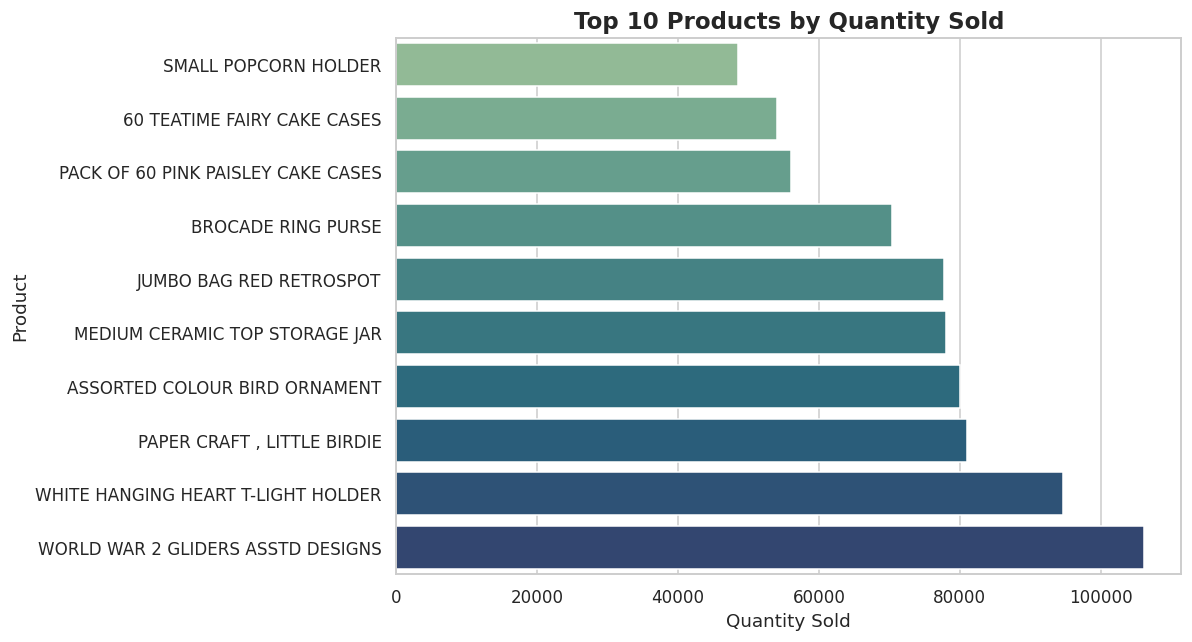

In [132]:
# Seaborn chart 1: Top 10 products by quantity sold
top_products_df = top_products.sort_values().reset_index()
top_products_df.columns = ["Description", "Quantity"]

plt.figure(figsize=(11, 6))
sns.barplot(data=top_products_df, x="Quantity", y="Description",
            hue="Description", palette="crest", legend=False)
plt.title("Top 10 Products by Quantity Sold", fontsize=15, weight="bold")
plt.xlabel("Quantity Sold")
plt.ylabel("Product")
plt.tight_layout()
plt.show()


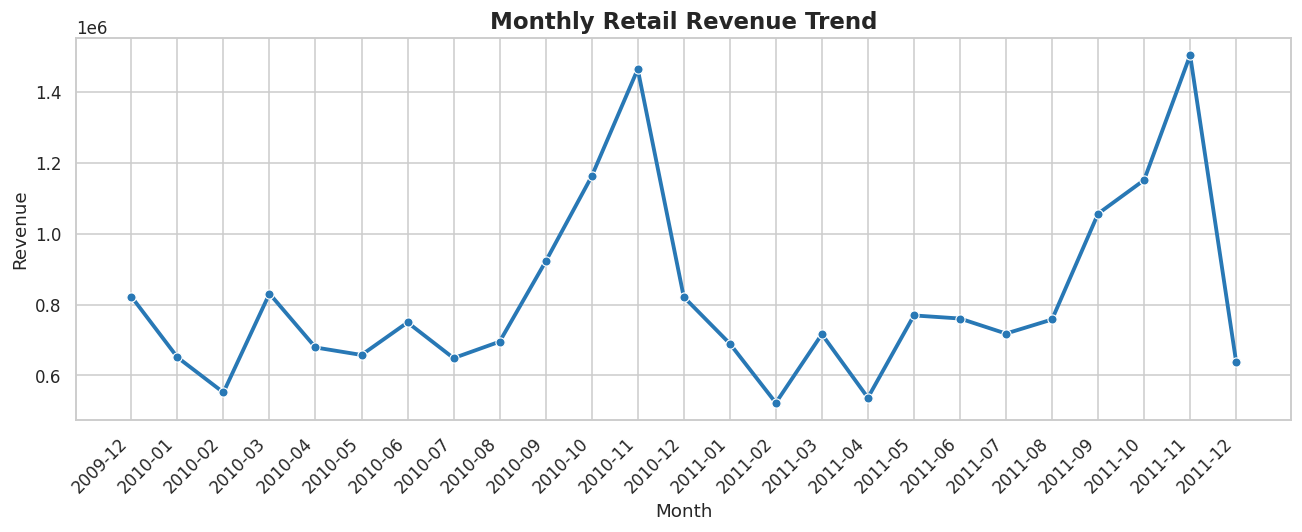

In [133]:
# Seaborn chart 2: Monthly revenue trend
monthly_df = monthly_sales.rename("Revenue").reset_index()
monthly_df.columns = ["Month", "Revenue"]

plt.figure(figsize=(12, 5))
sns.lineplot(data=monthly_df, x="Month", y="Revenue",
             marker="o", linewidth=2.5, color="#2878B5")
plt.title("Monthly Retail Revenue Trend", fontsize=15, weight="bold")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


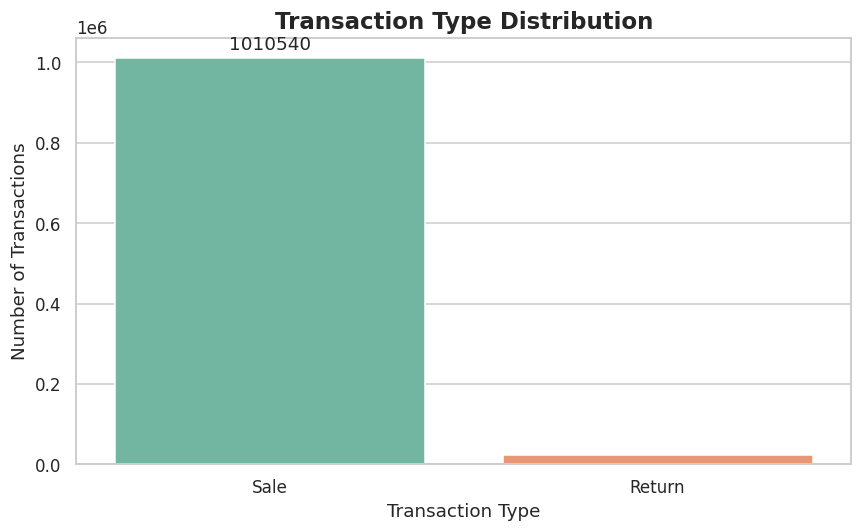

In [134]:
# Seaborn chart 3: Transaction type distribution
plt.figure(figsize=(8, 5))
order = df["TransactionType"].value_counts().index
ax = sns.countplot(data=df, x="TransactionType", order=order,
                   hue="TransactionType", palette="Set2", legend=False)
ax.bar_label(ax.containers[0], fmt="%d", padding=3)
plt.title("Transaction Type Distribution", fontsize=15, weight="bold")
plt.xlabel("Transaction Type")
plt.ylabel("Number of Transactions")
plt.tight_layout()
plt.show()


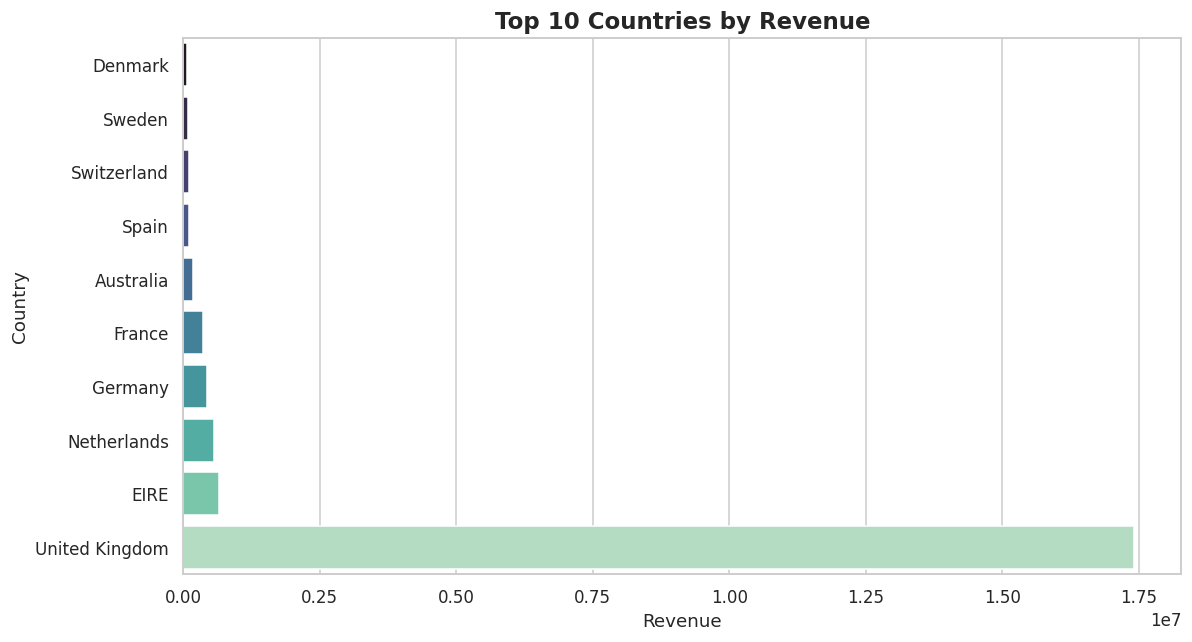

In [135]:
# Seaborn chart 4: Revenue by top 10 countries
country_plot = country_sales.sort_values(ascending=True).rename("Revenue").reset_index()
country_plot.columns = ["Country", "Revenue"]

plt.figure(figsize=(11, 6))
sns.barplot(data=country_plot, x="Revenue", y="Country",
            hue="Country", palette="mako", legend=False)
plt.title("Top 10 Countries by Revenue", fontsize=15, weight="bold")
plt.xlabel("Revenue")
plt.ylabel("Country")
plt.tight_layout()
plt.show()


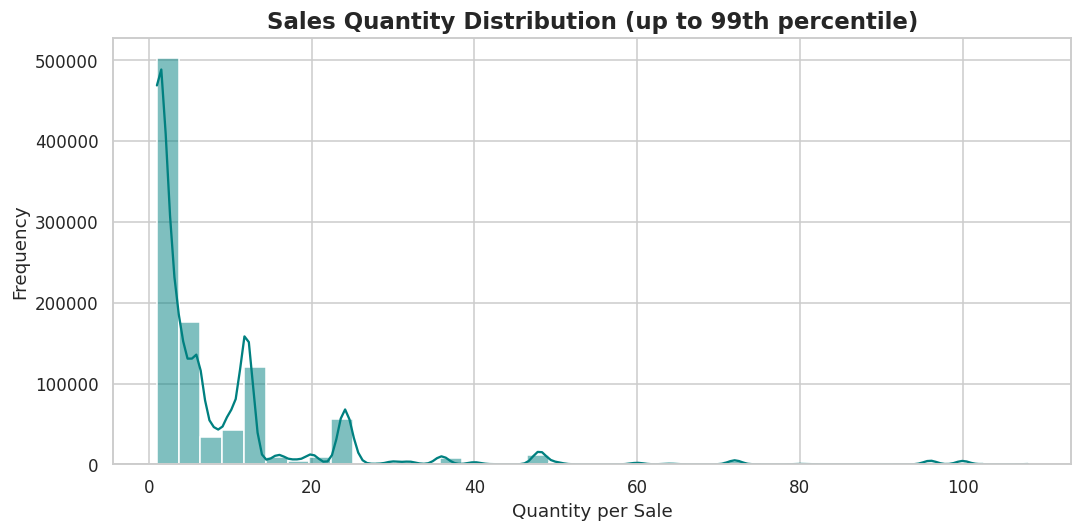

In [136]:
# Seaborn chart 5: Distribution of sales quantity
# Limit the display to the 99th percentile so extreme bulk orders do not hide the main pattern.
quantity_limit = sales["Quantity"].quantile(0.99)
quantity_plot = sales.loc[sales["Quantity"] <= quantity_limit, "Quantity"]

plt.figure(figsize=(10, 5))
sns.histplot(x=quantity_plot, bins=40, kde=True, color="teal")
plt.title("Sales Quantity Distribution (up to 99th percentile)",
          fontsize=15, weight="bold")
plt.xlabel("Quantity per Sale")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()


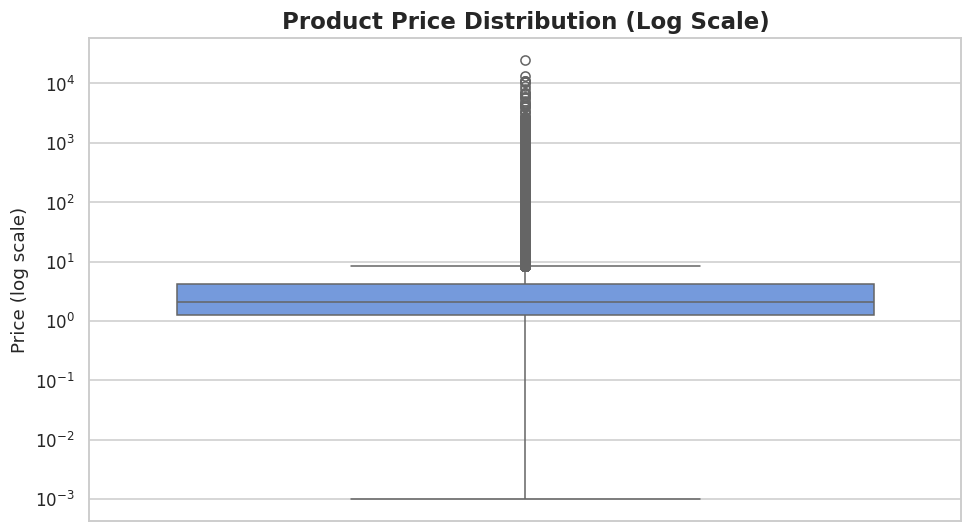

In [137]:
# Seaborn chart 6: Product price distribution
# Use a log scale to make the highly skewed price distribution easier to inspect.
price_plot = sales.loc[sales["Price"] > 0, "Price"]

plt.figure(figsize=(9, 5))
sns.boxplot(y=price_plot, color="cornflowerblue")
plt.yscale("log")
plt.title("Product Price Distribution (Log Scale)", fontsize=15, weight="bold")
plt.ylabel("Price (log scale)")
plt.tight_layout()
plt.show()


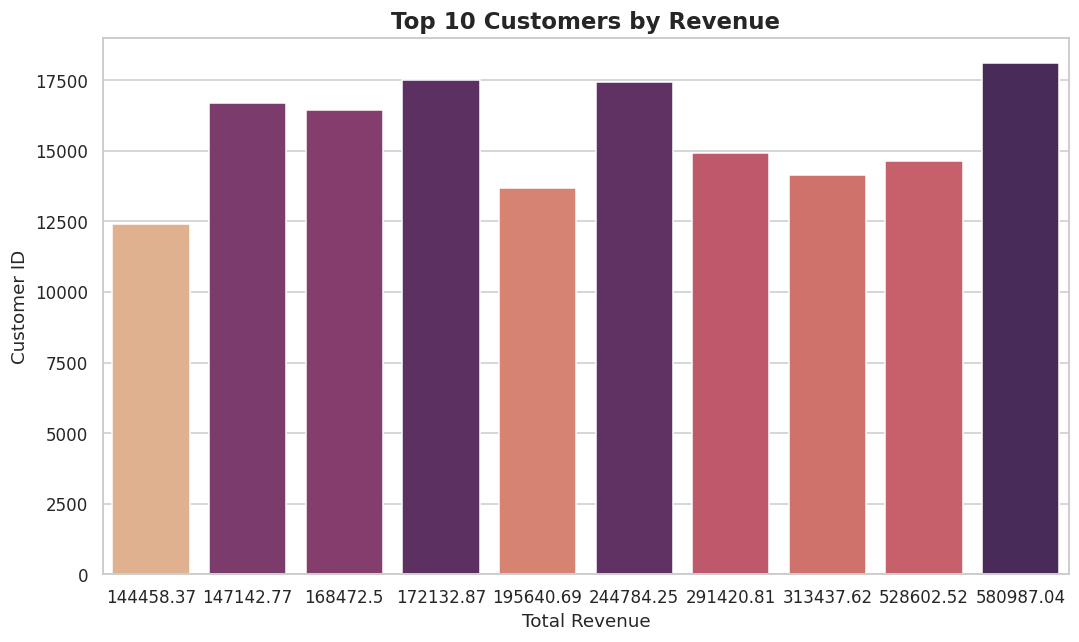

In [138]:
# Seaborn chart 7: Top 10 customers by revenue
customer_sales = sales.dropna(subset=["Customer ID"]).copy()
top_customers = (
    customer_sales.groupby("Customer ID")["TotalAmount"]
    .sum().nlargest(10).sort_values().reset_index()
)

plt.figure(figsize=(10, 6))
sns.barplot(data=top_customers, x="TotalAmount", y="Customer ID",
            hue="Customer ID", palette="flare", legend=False)
plt.title("Top 10 Customers by Revenue", fontsize=15, weight="bold")
plt.xlabel("Total Revenue")
plt.ylabel("Customer ID")
plt.tight_layout()
plt.show()


Total Returned Transactions: 22496
Total Returned Quantity: 1046134


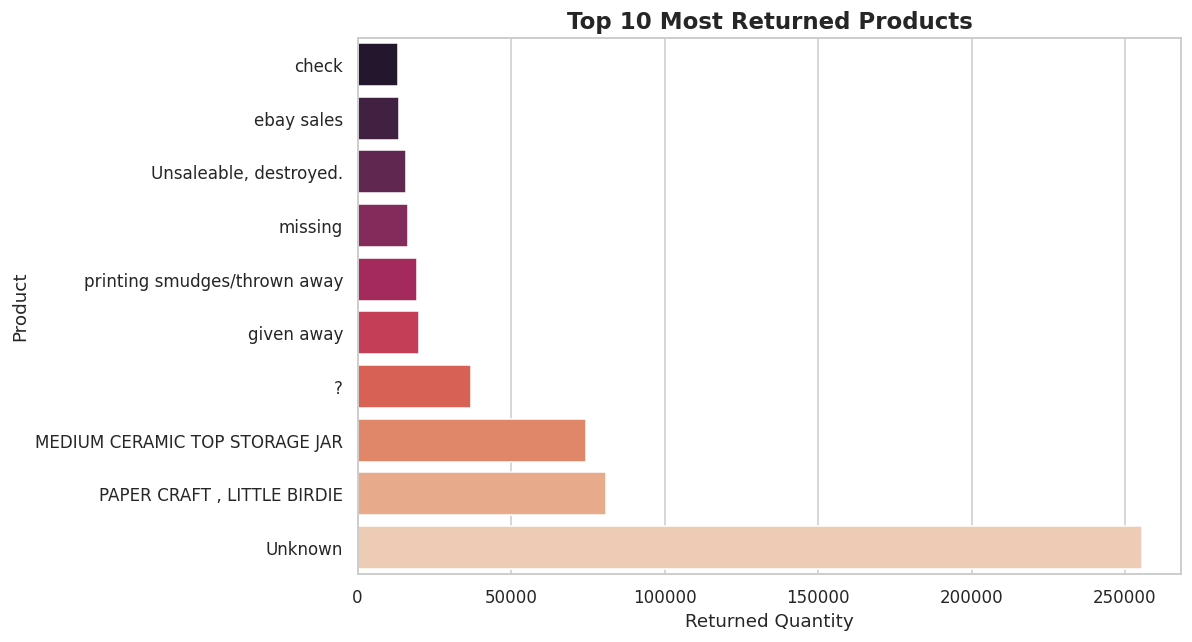

In [139]:
# Seaborn chart 8: Top 10 most returned products
returns = df[df["Quantity"] < 0].copy()

print("Total Returned Transactions:", len(returns))
print("Total Returned Quantity:", abs(returns["Quantity"].sum()))

top_returns = (
    returns.groupby("Description")["Quantity"].sum().abs()
    .nlargest(10).sort_values().rename("Returned Quantity").reset_index()
)
top_returns.columns = ["Description", "Returned Quantity"]

if not top_returns.empty:
    plt.figure(figsize=(11, 6))
    sns.barplot(data=top_returns, x="Returned Quantity", y="Description",
                hue="Description", palette="rocket", legend=False)
    plt.title("Top 10 Most Returned Products", fontsize=15, weight="bold")
    plt.xlabel("Returned Quantity")
    plt.ylabel("Product")
    plt.tight_layout()
    plt.show()
else:
    print("No returned transactions found.")


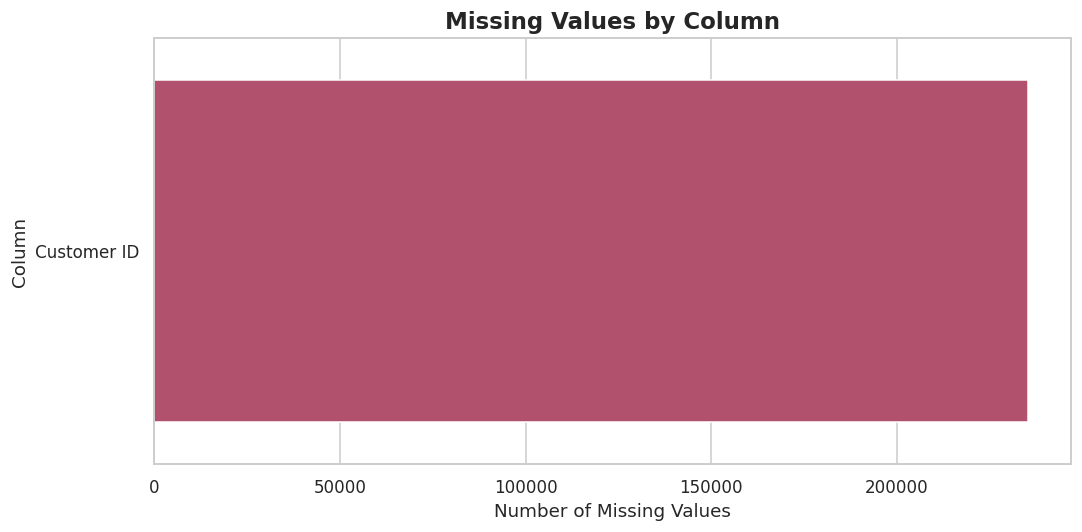

In [140]:
# Seaborn chart 9: Missing values by column
missing = df.isnull().sum().rename("Missing Values").reset_index()
missing.columns = ["Column", "Missing Values"]
missing = missing[missing["Missing Values"] > 0].sort_values("Missing Values")

if not missing.empty:
    plt.figure(figsize=(10, 5))
    sns.barplot(data=missing, x="Missing Values", y="Column",
                hue="Column", palette="flare", legend=False)
    plt.title("Missing Values by Column", fontsize=15, weight="bold")
    plt.xlabel("Number of Missing Values")
    plt.ylabel("Column")
    plt.tight_layout()
    plt.show()
else:
    print("Great! No missing values remain in the cleaned dataset.")


In [141]:
print("Final Dataset Shape:", df.shape)
print("Remaining Duplicates:", df.duplicated().sum())
print("\nMissing Values:")
print(df.isnull().sum())

print("\nNegative Quantities:", (df['Quantity'] < 0).sum())
print("Negative Prices:", (df['Price'] < 0).sum())

Final Dataset Shape: (1033036, 10)
Remaining Duplicates: 0

Missing Values:
Invoice                 0
StockCode               0
Description             0
Quantity                0
InvoiceDate             0
Price                   0
Customer ID        235151
Country                 0
TransactionType         0
TotalAmount             0
dtype: int64

Negative Quantities: 22496
Negative Prices: 5


In [142]:
# Final data quality summary
quality_report = pd.DataFrame({
    "Check": [
        "Remaining records", "Total columns", "Missing values",
        "Duplicate records", "Negative quantities", "Zero quantities",
        "Negative prices", "Zero prices"
    ],
    "Result": [
        len(df), len(df.columns), int(df.isnull().sum().sum()),
        int(df.duplicated().sum()), int((df["Quantity"] < 0).sum()),
        int((df["Quantity"] == 0).sum()), int((df["Price"] < 0).sum()),
        int((df["Price"] == 0).sum())
    ]
})
display(quality_report)

,Check,Result
0,Remaining records,1033036
1,Total columns,10
2,Missing values,235151
3,Duplicate records,0
4,Negative quantities,22496
5,Zero quantities,0
6,Negative prices,5
7,Zero prices,6014


In [143]:
# Export the cleaned dataset
output_file = "DataPrep_Cleaned_Transactions.csv"
df.to_csv(output_file, index=False)
print("Cleaned dataset saved as:", output_file)

Cleaned dataset saved as: DataPrep_Cleaned_Transactions.csv


In [144]:
# Download the cleaned CSV to your computer
from google.colab import files
files.download("DataPrep_Cleaned_Transactions.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>